# Synthetic HF population (delivery plan, step 1.14)

Distributions of the 10,000 patients from `sim.population.generate_patients`, seed 42. Assumptions are listed in `src/sim/README.md` §7.

Re-run: `uv run jupyter nbconvert --to notebook --execute --inplace testing/notebooks/population.ipynb`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sim.population import generate_patients, load_reference

ref = load_reference()
patients, mmg = generate_patients(42, ref)
comuni = ref['comuni']
print(len(patients), 'patients,', len(mmg), 'MMG,', mmg.coop_id.nunique(), 'cooperatives')
patients.head()

10000 patients, 540 MMG, 16 cooperatives


,patient_id,sex,age,comune_istat,asst_id,mmg_id,lives_alone,ref_facility_id,distance_km,conditions
0,p_00001,F,81,020042,asst_mantova,mmg_533,True,osp_A,44.8,"[HF, T2D]"
1,p_00002,M,73,019041,asst_crema,mmg_012,False,osp_C,14.7,[HF]
2,p_00003,F,81,020027,asst_mantova,mmg_472,True,osp_A,28.3,[HF]
3,p_00004,F,91,020036,asst_mantova,mmg_371,False,osp_A,36.2,[HF]
4,p_00005,M,92,020066,asst_mantova,mmg_340,True,osp_A,33.9,[HF]


## Age and sex

HF patients are sampled from ISTAT's population weighted by an assumed prevalence that rises with age, so the pyramid leans towards 75–89.

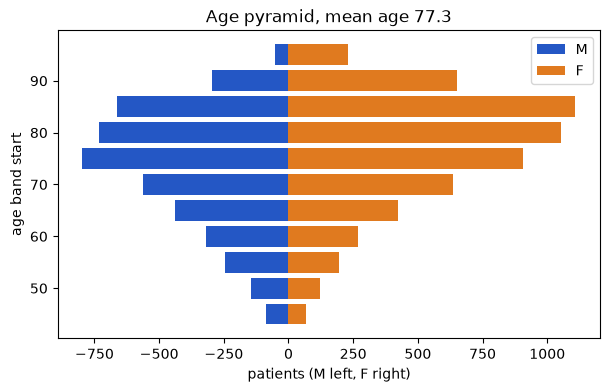

In [2]:
bands = (patients.age // 5 * 5).clip(upper=95)
pyr = patients.groupby([bands, 'sex']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(pyr.index, -pyr['M'], height=4, color='#2457c5', label='M')
ax.barh(pyr.index, pyr['F'], height=4, color='#e07a1f', label='F')
ax.set_xlabel('patients (M left, F right)'); ax.set_ylabel('age band start'); ax.legend()
ax.set_title(f'Age pyramid, mean age {patients.age.mean():.1f}'); plt.show()

## Patients per ASST against the population aged 65+

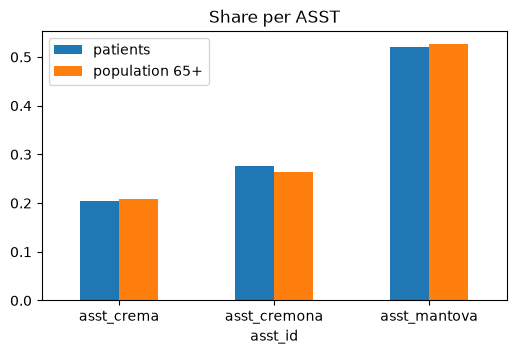

,patients,population 65+
asst_id,,
asst_crema,0.204,0.209
asst_cremona,0.276,0.265
asst_mantova,0.520,0.527


In [3]:
share = pd.DataFrame({'patients': patients.asst_id.value_counts(normalize=True),
                      'population 65+': comuni.groupby('asst_id').population_65plus.sum() / comuni.population_65plus.sum()})
share.plot.bar(figsize=(6, 3.5), rot=0, title='Share per ASST'); plt.show(); share.round(3)

## Living alone by age and sex

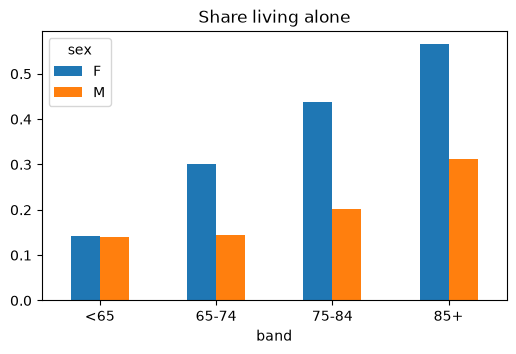

sex,F,M
band,,
<65,0.142,0.139
65-74,0.301,0.145
75-84,0.438,0.202
85+,0.566,0.312


In [4]:
alone = patients.assign(band=pd.cut(patients.age, [0, 65, 75, 85, 120], right=False,
                                      labels=['<65', '65-74', '75-84', '85+']))
tab = alone.groupby(['band', 'sex'], observed=True).lives_alone.mean().unstack()
tab.plot.bar(figsize=(6, 3.5), rot=0, title='Share living alone'); plt.show(); tab.round(3)

## Distance to the reference hospital

Maria (`p_00001`, Poggio Rusco) is marked.

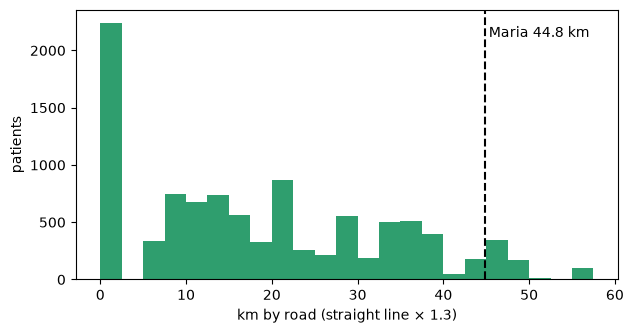

over 40 km: 853 patients


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(patients.distance_km, bins=np.arange(0, 60, 2.5), color='#2f9e6e')
maria = patients.set_index('patient_id').loc['p_00001', 'distance_km']
ax.axvline(maria, color='k', ls='--'); ax.text(maria + 0.5, ax.get_ylim()[1] * 0.9, f'Maria {maria} km')
ax.set_xlabel('km by road (straight line × 1.3)'); ax.set_ylabel('patients'); plt.show()
print('over 40 km:', (patients.distance_km > 40).sum(), 'patients')

## MMG and cooperatives

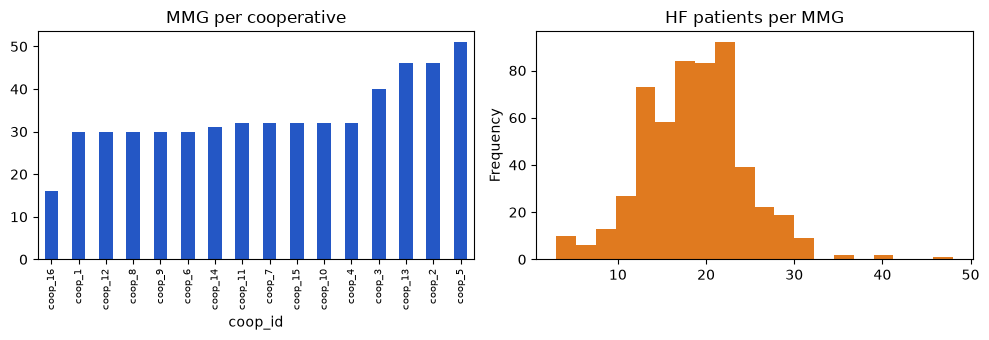

In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.5))
mmg.groupby('coop_id').size().sort_values().plot.bar(ax=a, title='MMG per cooperative', color='#2457c5')
a.tick_params(axis='x', labelsize=7)
patients.groupby('mmg_id').size().plot.hist(ax=b, bins=20, title='HF patients per MMG', color='#e07a1f')
plt.tight_layout(); plt.show()

## Where the patients live

One dot per comune at its centroid, sized by HF patients and coloured by cooperative.

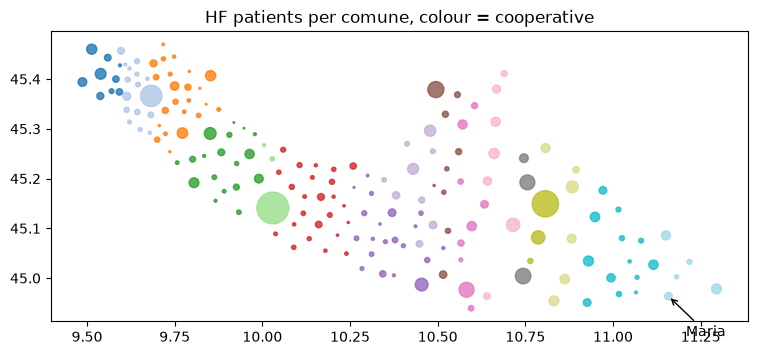

In [7]:
per = patients.groupby('comune_istat').size().rename('n').reset_index().merge(comuni, on='comune_istat')
coop = mmg.drop_duplicates('comune_istat').set_index('comune_istat').coop_id.str[5:].astype(int)
fig, ax = plt.subplots(figsize=(9, 4.5))
sc = ax.scatter(per.lon, per.lat, s=per.n / 2, c=per.comune_istat.map(coop), cmap='tab20', alpha=0.8)
m = comuni.set_index('comune_istat').loc['020042']
ax.annotate('Maria', (m.lon, m.lat), xytext=(m.lon + 0.05, m.lat - 0.08), arrowprops={'arrowstyle': '->'})
ax.set_aspect(1 / np.cos(np.radians(45.2))); ax.set_title('HF patients per comune, colour = cooperative')
plt.show()